In [1]:
from Recording.index import loadRecording
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
pd.set_option('display.max_columns', None)

# GRAVAÇÃO
- Ensaio de pêndulo `test1/rolling_z`: o Kernel-120 (`target_`) e a Seatex MRU 5 de referência (`ref_`) presos no mesmo braço de ~1,9 m, gravados juntos pelo computador a 10 Hz, uma linha por mensagem da Seatex
- Escolhido entre os 11 ensaios brutos por ser contínuo (sem buraco nem mensagem perdida) e por ter a referência coerente parada: o roll que a Seatex informa bate com o que a gravidade dá no acelerômetro dela a 0,02°
- 13 s parado, o pêndulo é solto e balança em roll por 150 s até parar, mais 66 s parado: os dois regimes no mesmo registro, sem emenda

In [2]:
RECORDING = '../../Analysis/Calibration_OLD/Pendulum_Compare_MRU/Format/files/test1/rolling_z'

df = loadRecording(RECORDING)
df.head(3)

,time,static,target_ax,target_ay,target_az,target_wx,target_wy,target_wz,target_roll,target_pitch,target_yaw,ref_roll,ref_pitch,ref_yaw,ref_heave,ref_q0,ref_q1,ref_q2,ref_q3,ref_ax,ref_ay,ref_az,ref_wx,ref_wy,ref_wz
0,0.0,True,0.246971,-0.410624,9.778721,-0.07912,0.05244,-0.14963,-1.387,-2.473,3.030,-92.188909,0.500249,-4.101805,0.5481,-0.6933,0.7198,-0.02880,0.02168,0.1148,9.779,0.3699,-0.029301,0.022271,0.004696
1,0.1,True,0.268271,-0.458598,9.757764,0.29277,-0.33624,0.30280,-1.388,-2.481,3.033,-92.188909,0.499848,-4.102951,0.5439,-0.6933,0.7198,-0.02881,0.02169,0.1137,9.777,0.3691,-0.017424,0.014146,-0.017097
2,0.2,True,0.252335,-0.420372,9.739690,0.07205,-0.14049,-0.35499,-1.389,-2.472,3.046,-92.188909,0.499161,-4.104670,0.5398,-0.6932,0.7198,-0.02882,0.02170,0.1148,9.779,0.3693,-0.041259,0.018254,-0.003837


# CONVERSÃO
- **Tempo:** relógio da própria Seatex (`sample_time`, passo exato de 0,1 s); o do computador oscila entre 0,089 e 0,114 s só pela fila da porta serial
- **Kernel, eixos crus**, os mesmos que o firmware recebe: acelerômetro de $g\cdot10^6$ do modo HR para m/s² ($g_0$ = 9,80665), giro de $°/s\cdot10^5$ para °/s e os ângulos do AHRS interno dele de $°\cdot10^3$ para graus
- **Seatex:** ângulos e taxas de rad para graus, quaternion, acelerômetro em m/s² e `la_pos_mon_d` (heave no ponto de medida, positivo para baixo) como `ref_heave`
- **`static`:** a referência está parada quando $\lVert\omega_{ref}\rVert$ fica abaixo de 0,3 °/s por 3 s seguidos (a Seatex parada mede 0,02 °/s de ruído; 3 s passa de um período do pêndulo, então a inversão do balanço não conta como repouso)

In [3]:
edges    = np.flatnonzero(np.diff(df.static.astype(int))) + 1
bounds   = np.r_[0, edges, len(df)]
segments = pd.DataFrame([{'trecho': 'repouso' if df.static[a] else 'balanço', 'início (s)': df.time[a], 'fim (s)': df.time[b - 1], 'duração (s)': df.time[b - 1] - df.time[a], 'amostras': b - a} for a, b in zip(bounds[:-1], bounds[1:])])
segments

,trecho,início (s),fim (s),duração (s),amostras
0,repouso,0.0,13.3,13.3,134
1,balanço,13.4,163.9,150.5,1506
2,repouso,164.0,229.6,65.6,657


# VISUALIZAÇÃO

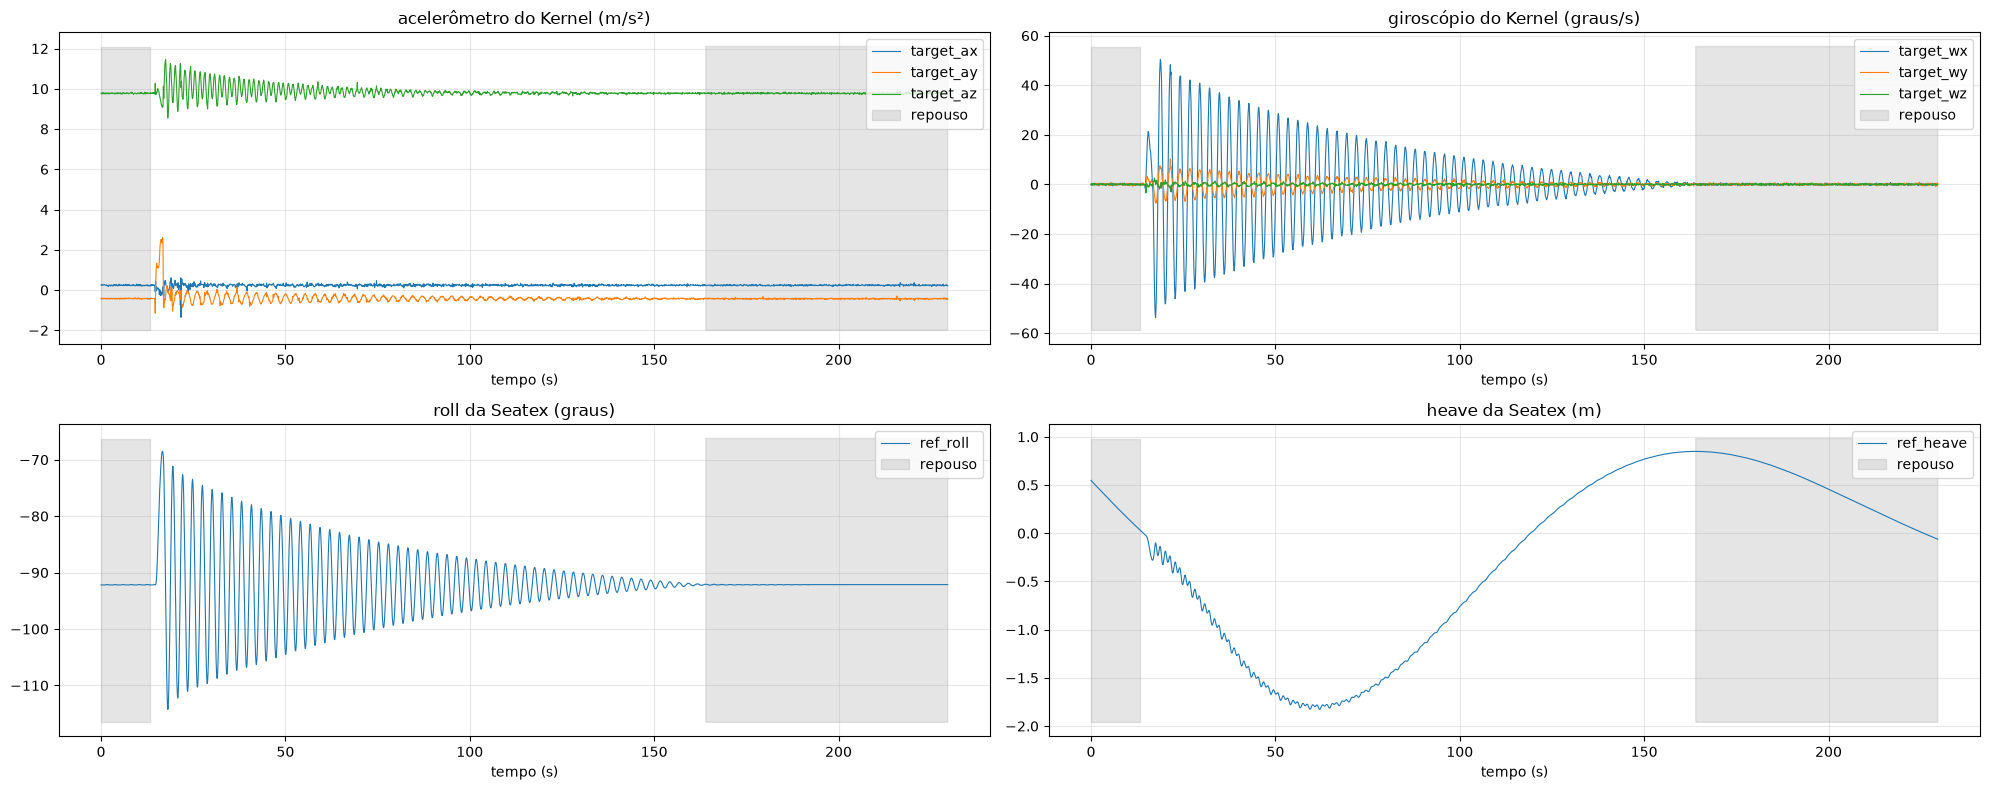

In [4]:
PANELS = {'acelerômetro do Kernel (m/s²)': ['target_ax', 'target_ay', 'target_az'], 'giroscópio do Kernel (graus/s)': ['target_wx', 'target_wy', 'target_wz'], 'roll da Seatex (graus)': ['ref_roll'], 'heave da Seatex (m)': ['ref_heave']}

plt.figure(figsize=(20, 8))

for i, (title, cols) in enumerate(PANELS.items()):
    plt.subplot(2, 2, i + 1)

    for col in cols:
        plt.plot(df.time, df[col], label=col, linewidth=0.8)

    plt.fill_between(df.time, *plt.ylim(), where=df.static, color='gray', alpha=0.2, label='repouso')
    plt.title(title); plt.xlabel('tempo (s)'); plt.grid(alpha=0.3); plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# SALVANDO DADOS
- Mesma convenção de colunas do `data.csv` do `Calibration` (`time`, `static`, `target_`, `ref_`), mas nos eixos crus do Kernel e sem buraco
- Para os dados a 100 Hz basta apontar `RECORDING` para a gravação nova; o Kernel deve sair em média (`Average_Output_Data` = 1): no modo instantâneo, o padrão, cada amostra carrega o ruído da taxa interna de 2 kHz

In [5]:
df.to_csv('data.csv', index=False, float_format='%.10g')
pd.read_csv('data.csv').describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
time,114.800000,66.323111,0.000000,229.600000
target_ax,0.234685,0.067587,-1.359516,0.607787
target_ay,-0.402090,0.236659,-1.149202,2.605254
target_az,9.825968,0.234820,8.548869,11.459316
target_wx,0.005015,12.639355,-53.677850,50.413160
target_wy,0.004175,1.827695,-7.527000,10.274610
target_wz,-0.012658,0.358768,-3.484510,2.593000
target_roll,-1.460432,0.810670,-4.817000,1.581000
target_pitch,-2.951562,5.727238,-24.173000,20.862000
target_yaw,4.331142,0.640619,3.030000,5.313000
